# Atelier 1 — Classification : identifier le type de panne

Ce notebook suit les questions du sujet. Le code partagé dans `src/` est commenté
en français. Les résultats enregistrés proviennent d'une exécution complète sur CPU,
avec une graine de 42. La cellule d'entraînement permet de refaire l'expérience.

**Avant de commencer :** suivre l'installation du README et sélectionner le Python
de l'environnement virtuel comme noyau. Dans Colab, cloner le dépôt, entrer dans
son dossier et installer les dépendances ; les commandes sont dans le README.

In [1]:
from pathlib import Path
import os
import sys

# Accepter un lancement depuis la racine du dépôt ou depuis notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir() and (ROOT.parent / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Cloner le dépôt et lancer ce notebook depuis son dossier.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
from IPython.display import display, Image
from src.data import download_data, load_regression, load_classification, NUMERIC, REG_FEATURES
from src.experiments import run_experiment, make_pipeline, parameter_grid
from src.models import MLP

# Le téléchargement est réutilisable et son empreinte est vérifiée à chaque appel.
download_data()

{'prices-split-adjusted.csv': {'kaggle': 'https://www.kaggle.com/datasets/dgawlik/nyse',
  'url': 'https://raw.githubusercontent.com/griffinschwab/NYSE-ML-Project/dfd0e9cf577d6fa2271957ab470c2c81c654bc6b/data/raw/prices-split-adjusted.csv',
  'sha256': '0a8e0505591c8ae8c545d6d9e7bb69735c18568745ef848bf4d01e1afd871ec5'},
 'predictive_maintenance.csv': {'kaggle': 'https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification',
  'url': 'https://raw.githubusercontent.com/beratcmn/machine-maintenance-prediction/9683ce9ccd58e29fb4ef39d116b16416606a2190/data/predictive_maintenance.csv',
  'sha256': 'ba1eb264c69e69258acb2df6991055afc93092b1be436a29d2e6037b0ebd80cc'}}

## 1. Nettoyer et comprendre les données

La cible **Failure Type** contient six classes, y compris `No Failure`.
`Target` est retirée des entrées car elle révèle déjà la présence d'une panne.
`UDI` et `Product ID` sont des identifiants : ils ne sont pas des mesures physiques.
Nous conservons cinq mesures numériques et la catégorie de produit `Type`.
Les mesures manquantes sont imputées par la médiane du train et standardisées.
La catégorie est imputée puis encodée. Les valeurs extrêmes ne sont pas supprimées
automatiquement : elles peuvent justement décrire une panne.

In [2]:
raw, prepared, parts = load_classification()
display(raw.head())
display(raw.isna().sum().to_frame('Valeurs manquantes'))
print('Doublons exacts :', raw.duplicated().sum())
display(parts['train'][NUMERIC].describe())
display(pd.DataFrame({name: frame['Failure Type'].value_counts()
                      for name, frame in parts.items()}))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


,Valeurs manquantes
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0


Doublons exacts : 0


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,300.011600,310.004871,1538.449857,40.024129,108.109143
std,2.004709,1.479887,180.062902,9.964098,63.741406
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1422.000000,33.300000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1611.000000,46.800000,163.000000
max,304.400000,313.700000,2886.000000,76.600000,253.000000


,train,validation,test
Failure Type,,,
No Failure,6756,1448,1448
Heat Dissipation Failure,78,17,17
Power Failure,67,14,14
Overstrain Failure,55,11,12
Tool Wear Failure,31,7,7
Random Failures,13,3,2


## 2. Séparer puis équilibrer les classes

Le partage 70 % / 15 % / 15 % est stratifié : chaque partition garde les six classes.
Nous appliquons **SMOTENC**, une extension de SMOTE pour les variables mixtes.
Elle crée des exemples minoritaires sans interpoler la catégorie du produit.
L'encodage one-hot vient après cette augmentation.

SMOTENC agit seulement sur les données d'entraînement de chaque fold. La validation
et le test conservent leur distribution naturelle. Cela évite d'évaluer le modèle
sur des exemples synthétiques trop proches du train.

In [3]:
display(make_pipeline('classification'))
print('Entrées :', NUMERIC + ['Type'])
print('Cible : Failure Type ; Target et identifiants exclus.')

,steps,"[('prepare', ...), ('balance', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formattin

Entrées : ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']
Cible : Failure Type ; Target et identifiants exclus.


## 3. Construire un MLP et rechercher les hyperparamètres

Un **MLP** est un réseau de couches entièrement connectées. Les couches cachées
utilisent ReLU. En régression, la sortie est une valeur et la loss est MSE.
En classification, la sortie contient six logits et la loss est l'entropie croisée.

`GridSearchCV` compare neuf configurations : taux d'apprentissage, architecture,
nombre d'époques et optimiseur. Il utilise trois folds, chronologiques avec purge
pour la régression, stratifiés pour la classification. Le score est la RMSE négative
en régression et le F1 macro en classification. Le test n'intervient pas dans ce choix.

In [4]:
# Afficher la grille réellement utilisée, pas seulement la configuration gagnante.
display(parameter_grid(quick=False))

[{'net__lr': [0.001, 0.01],
  'net__optimizer': ['adam'],
  'net__hidden': [(32,), (64, 32)],
  'net__epochs': [40, 80]},
 {'net__lr': [0.01],
  'net__optimizer': ['sgd'],
  'net__hidden': [(64, 32)],
  'net__epochs': [80]}]

## 4. Exécuter l'expérience et comparer les régularisations

Le modèle initial est comparé à Dropout, L2, arrêt anticipé et leur combinaison.
L'arrêt anticipé surveille la loss de validation, avec une patience de dix époques,
et restaure les meilleurs poids. Le modèle final est choisi sur la validation
(RMSE ou F1 macro). Les mesures et courbes de test sont calculées ensuite,
à partir des poids enregistrés à chaque époque ; elles ne guident pas l'entraînement.

Par défaut, nous lisons les résultats déjà produits. Passer `REENTRAINER` à `True`
pour refaire toute la recherche et les entraînements ; cela remplace les résultats
de cette partie dans `results/`. Le mode complet peut prendre quelques minutes.

In [5]:
TASK = 'classification'
REENTRAINER = False
output = ROOT / 'results' / TASK
if REENTRAINER or not (output / 'summary.json').exists():
    run_experiment(TASK, quick=False)

summary = json.loads((output / 'summary.json').read_text())
print('Mode enregistré :', summary['mode'])
print('Configuration CV :', summary['best_parameters_cv'])
print('Modèle choisi sur validation :', summary['selected_on_validation'])
print('Partitions :', summary['split_sizes'])
display(pd.read_csv(output / 'comparison.csv'))

Mode enregistré : full
Configuration CV : {'net__epochs': 80, 'net__hidden': [64, 32], 'net__lr': 0.01, 'net__optimizer': 'adam'}
Modèle choisi sur validation : dropout
Partitions : {'train': 7000, 'validation': 1500, 'test': 1500}


,model,epochs_run,selected_epoch,train_accuracy,train_balanced_accuracy,train_f1_macro,train_f1_weighted,validation_accuracy,validation_balanced_accuracy,validation_f1_macro,validation_f1_weighted,test_accuracy,test_balanced_accuracy,test_f1_macro,test_f1_weighted
0,initial,80,80,0.980000,0.949974,0.795902,0.983061,0.954000,0.572955,0.500027,0.961592,0.959333,0.633481,0.553909,0.966664
1,dropout,80,80,0.946429,0.975841,0.646627,0.962479,0.918667,0.644087,0.520836,0.943722,0.933333,0.679887,0.566801,0.954347
2,l2,80,80,0.920000,0.923717,0.546129,0.943696,0.900667,0.641094,0.470554,0.931574,0.912000,0.723824,0.509212,0.938992
3,early_stopping,13,3,0.908286,0.886507,0.559600,0.939210,0.892000,0.595495,0.473337,0.927839,0.899333,0.688254,0.539381,0.934874
4,combined,32,22,0.900429,0.917777,0.515369,0.931957,0.887333,0.659240,0.453793,0.923460,0.895333,0.734721,0.486110,0.929006


In [6]:
# Afficher le réseau retenu : 8 entrées après préparation pour les deux tâches.
params = summary['best_parameters_cv']
display(MLP(inputs=8, outputs=1 if TASK == 'regression' else 6,
            hidden=tuple(params['net__hidden']),
            dropout=.2 if summary['selected_on_validation'] in ['dropout', 'combined'] else 0.))

# Les neuf configurations et leur dispersion entre folds sont consultables.
grid = pd.read_csv(output / 'grid_search.csv')
display(grid[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']]
        .sort_values('rank_test_score'))

MLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=6, bias=True)
  )
)

,rank_test_score,mean_test_score,std_test_score,params
7,1,0.557858,0.018067,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
6,2,0.550704,0.015527,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
5,3,0.545849,0.007304,"{'net__epochs': 80, 'net__hidden': (32,), 'net..."
3,4,0.535448,0.014943,"{'net__epochs': 40, 'net__hidden': (64, 32), '..."
1,5,0.525811,0.007896,"{'net__epochs': 40, 'net__hidden': (32,), 'net..."
8,6,0.520674,0.003468,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
2,7,0.509776,0.004754,"{'net__epochs': 40, 'net__hidden': (64, 32), '..."
4,8,0.480734,0.017724,"{'net__epochs': 80, 'net__hidden': (32,), 'net..."
0,9,0.437819,0.003310,"{'net__epochs': 40, 'net__hidden': (32,), 'net..."


## 5. Visualiser et interpréter

Une loss qui diminue sur le train mais augmente sur validation signale un possible
surapprentissage. Une régularisation n'est pas automatiquement bénéfique : elle
peut aussi empêcher le réseau d'apprendre suffisamment.

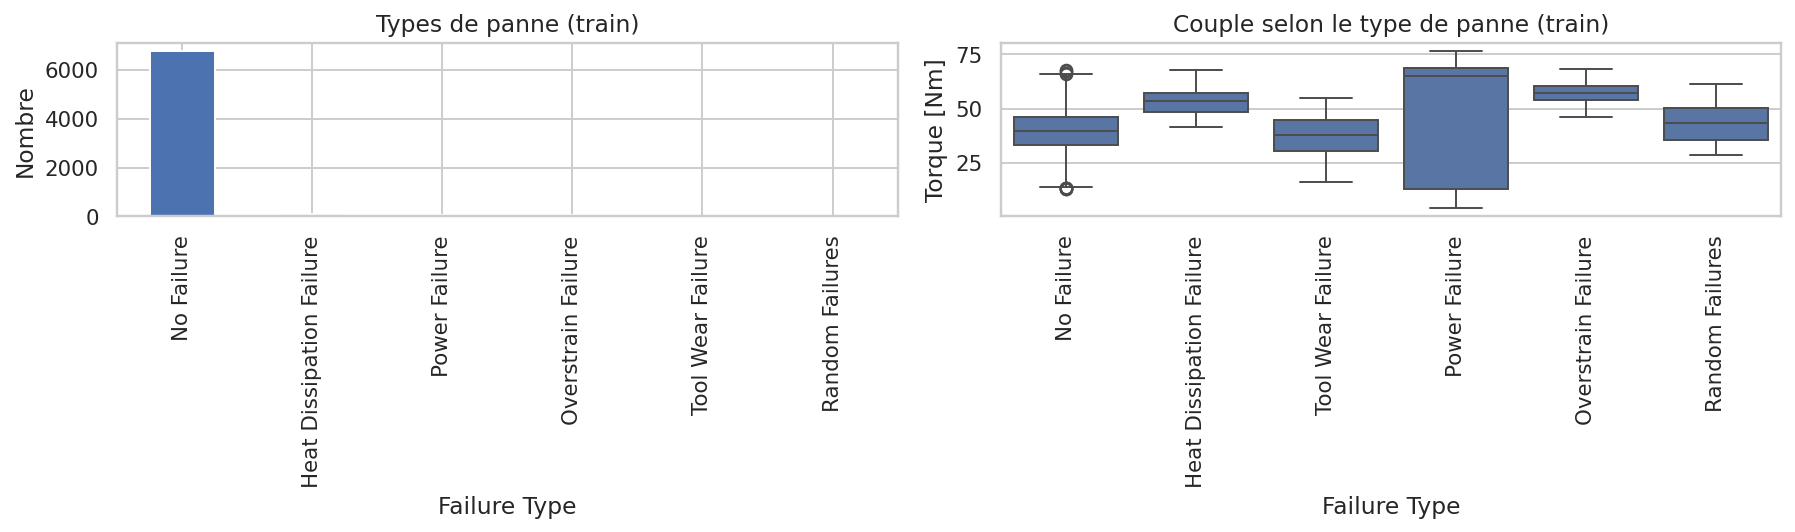

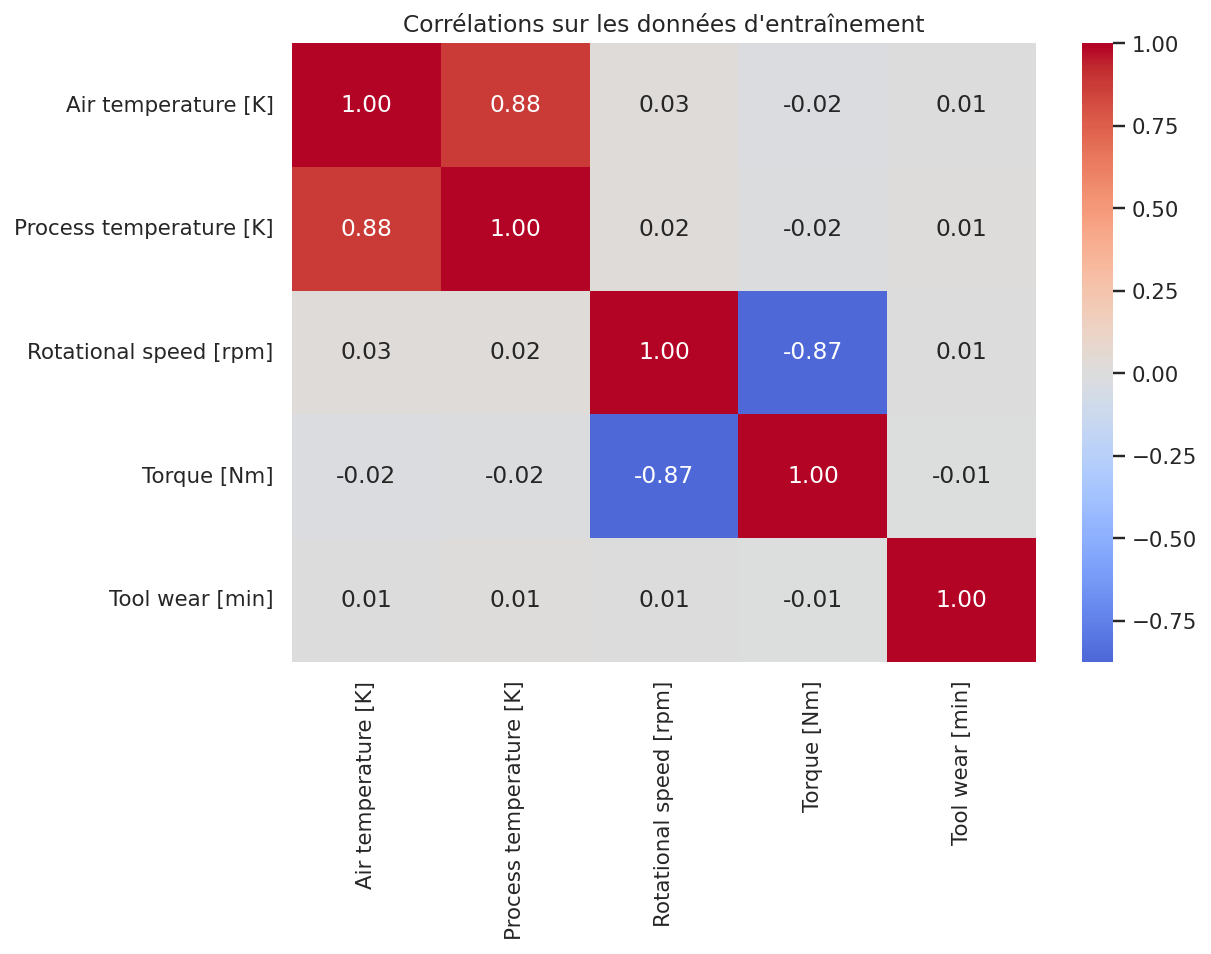

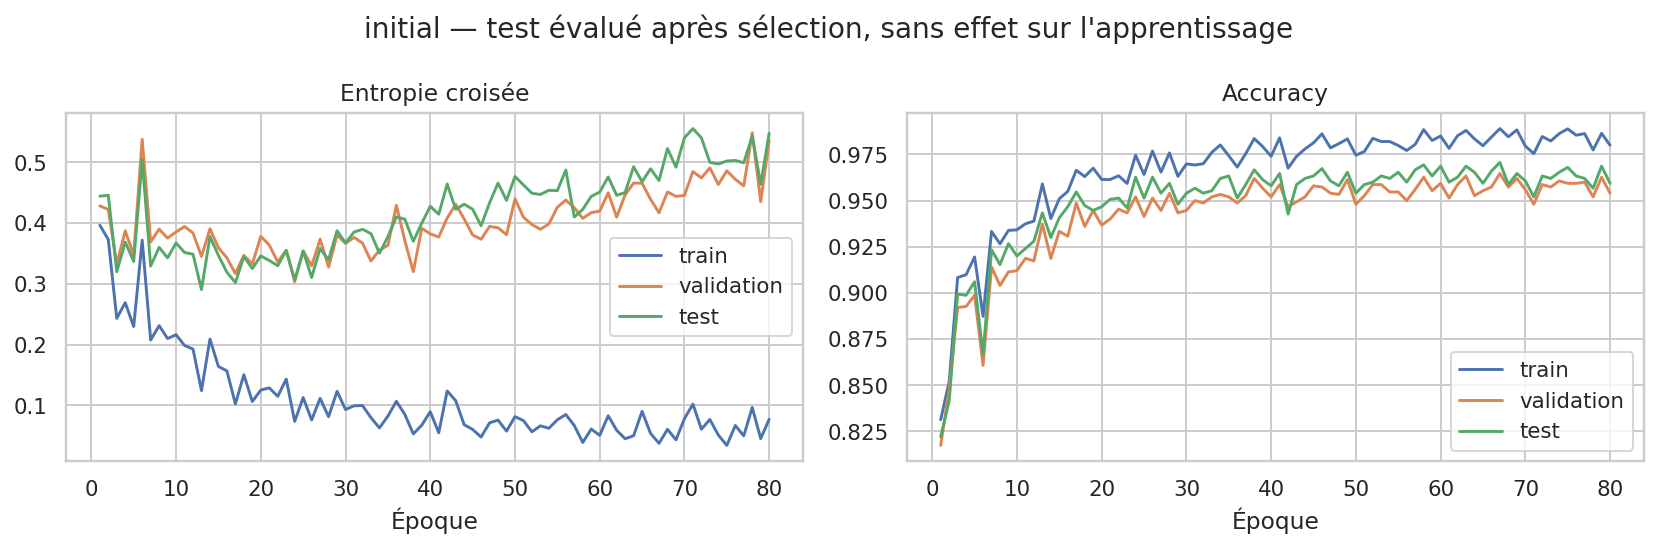

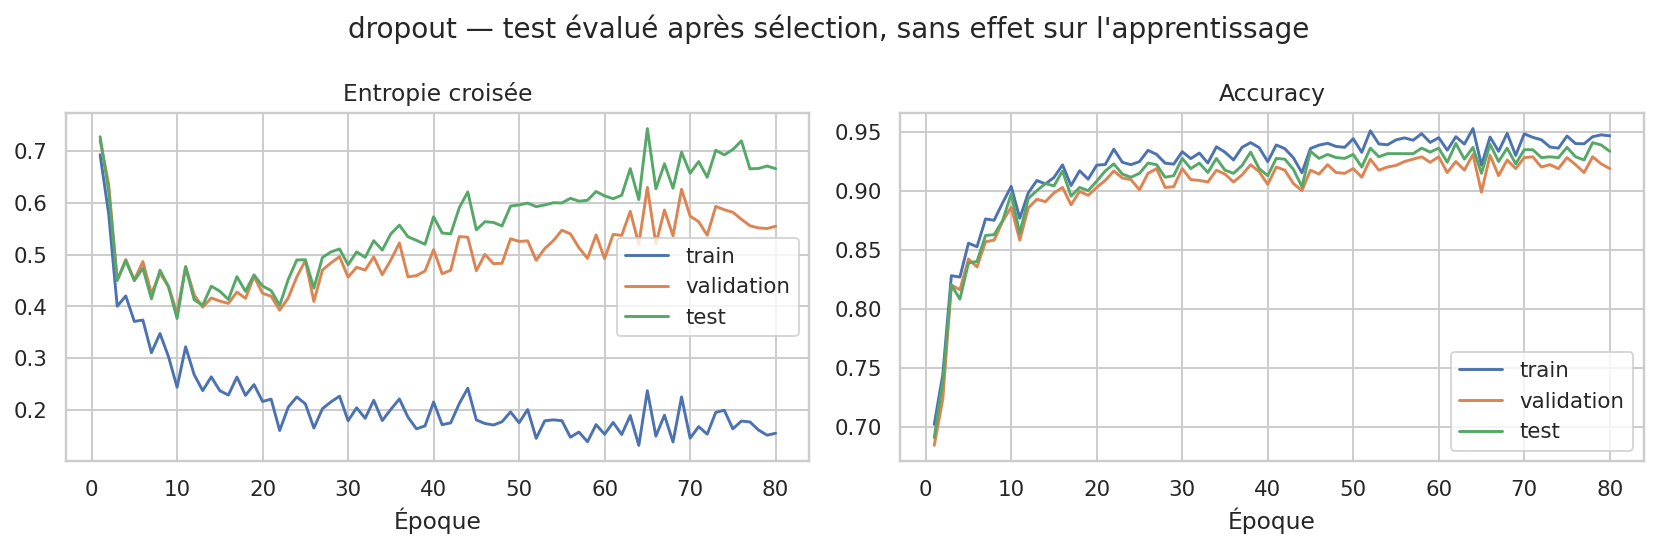

In [7]:
display(Image(filename=str(output / 'eda.png')))
display(Image(filename=str(output / 'correlations.png')))
display(Image(filename=str(output / 'curves_initial.png')))
display(Image(filename=str(output / ('curves_' + summary['selected_on_validation'] + '.png'))))

### Pourquoi l'accuracy seule peut tromper

La majorité des machines ne présentent pas de panne. Prédire toujours `No Failure`
peut donc donner une bonne accuracy tout en ratant toutes les pannes.
Le **rappel / sensibilité** mesure la part de cas d'une classe détectés ; la précision
mesure la fiabilité des alertes ; le F1 les combine. Le **F1 macro** traite chaque
classe à égalité. Le support indique combien d'exemples soutiennent chaque mesure.
Les classes très rares ont des résultats particulièrement incertains.

,avant,apres
Heat Dissipation Failure,78,6756
No Failure,6756,6756
Overstrain Failure,55,6756
Power Failure,67,6756
Random Failures,13,6756
Tool Wear Failure,31,6756


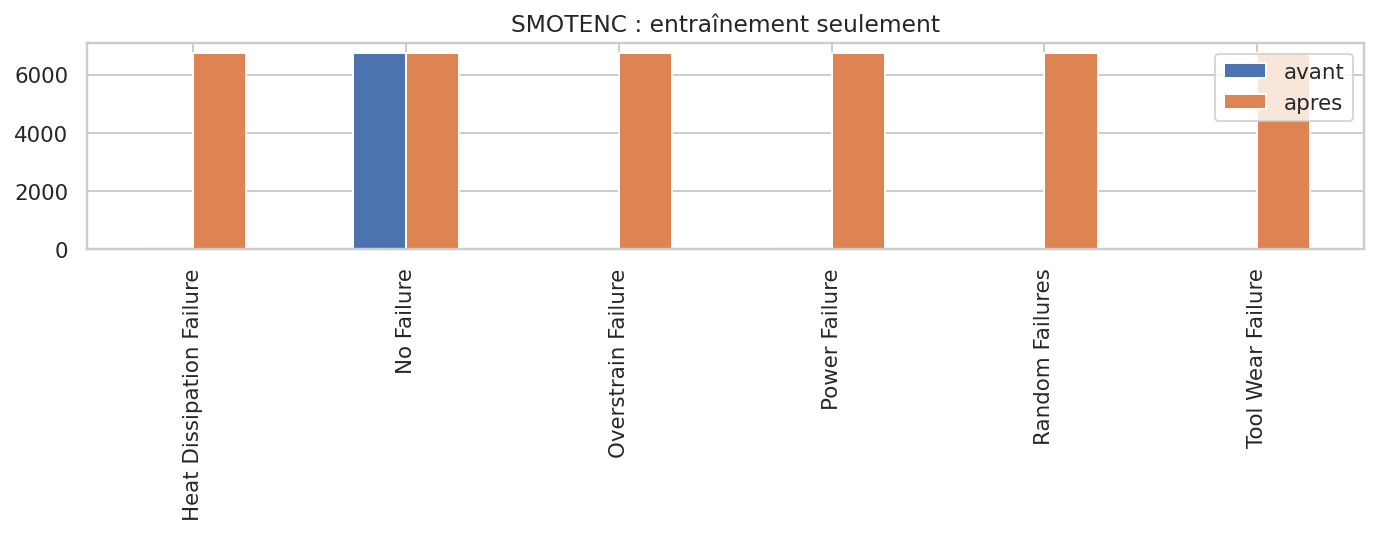

Rapport : train


,precision,recall,f1-score,support
Heat Dissipation Failure,0.733333,0.987179,0.841530,78.000000
No Failure,0.999687,0.944790,0.971463,6756.000000
Overstrain Failure,0.753425,1.000000,0.859375,55.000000
Power Failure,0.614679,1.000000,0.761364,67.000000
Random Failures,0.112150,0.923077,0.200000,13.000000
Tool Wear Failure,0.140271,1.000000,0.246032,31.000000
accuracy,0.946429,0.946429,0.946429,0.946429
macro avg,0.558924,0.975841,0.646627,7000.000000
weighted avg,0.985645,0.946429,0.962479,7000.000000


Rapport : test


,precision,recall,f1-score,support
Heat Dissipation Failure,0.629630,1.000000,0.772727,17.000000
No Failure,0.994864,0.936464,0.964781,1448.000000
Overstrain Failure,0.705882,1.000000,0.827586,12.000000
Power Failure,0.666667,1.000000,0.800000,14.000000
Random Failures,0.000000,0.000000,0.000000,2.000000
Tool Wear Failure,0.020408,0.142857,0.035714,7.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.502909,0.679887,0.566801,1500.000000
weighted avg,0.979476,0.933333,0.954347,1500.000000


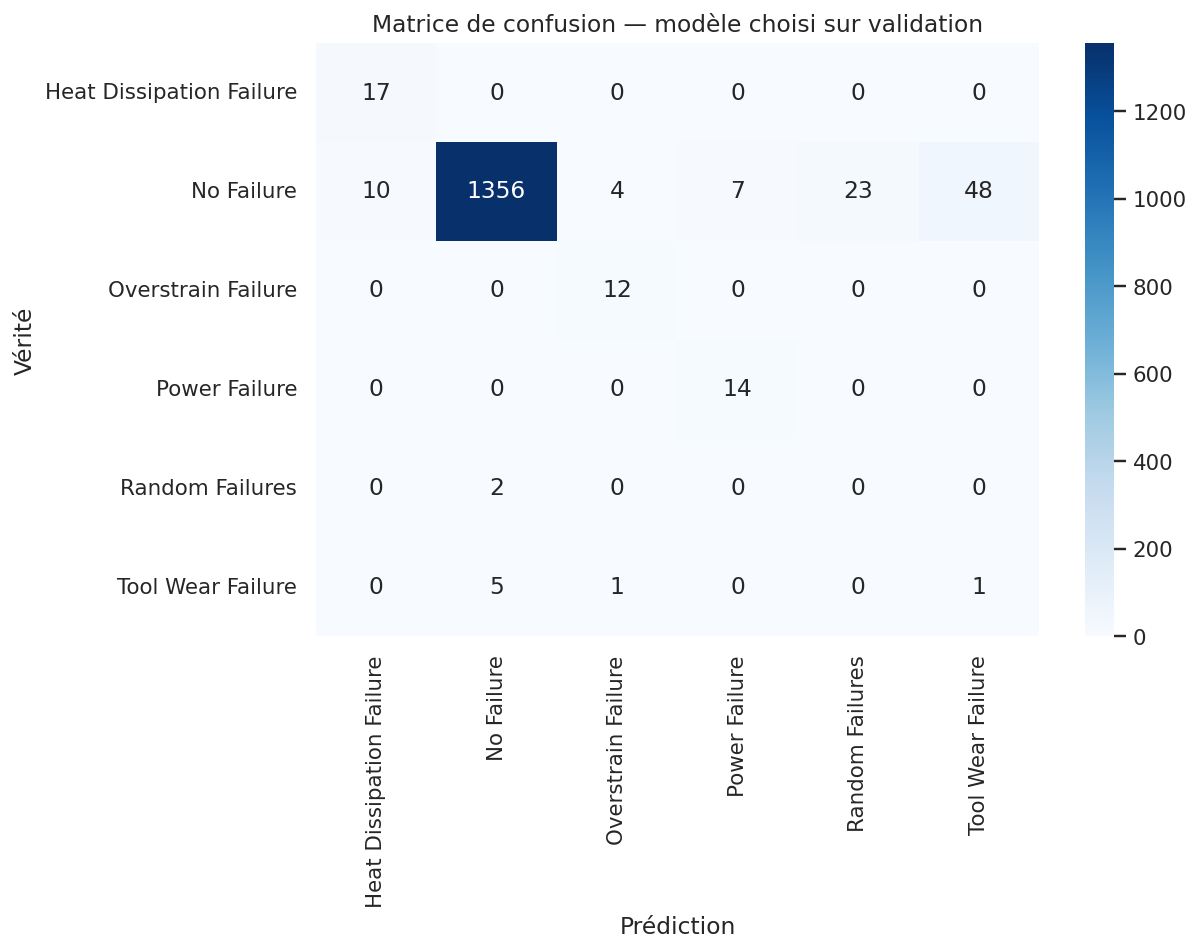

Référence : toujours la classe majoritaire


,accuracy,balanced_accuracy,f1_macro,f1_weighted
train,0.965143,0.166667,0.163710,0.948023
validation,0.965333,0.166667,0.163727,0.948306
test,0.965333,0.166667,0.163727,0.948306


In [8]:
display(pd.read_csv(output / 'class_balance.csv', index_col=0))
display(Image(filename=str(output / 'class_balance.png')))
chosen = summary['selected_on_validation']
for partition in ['train', 'test']:
    print('Rapport :', partition)
    display(pd.read_csv(output / f'report_{chosen}_{partition}.csv', index_col=0))
display(Image(filename=str(output / 'confusion_matrix.png')))
print('Référence : toujours la classe majoritaire')
display(pd.DataFrame(summary['reference']).T)

## 6. Bilan à discuter

- Distinguer données d'entraînement, validation et test pour éviter une évaluation optimiste.
- Ajuster les prétraitements dans chaque fold de la recherche d'hyperparamètres.
- Choisir une métrique adaptée et comparer à une référence simple.
- Vérifier l'effet réel des régularisations, sans supposer qu'elles améliorent tout.
- Relier les conclusions aux effectifs et aux limites du jeu de données.

Le README rassemble les résultats mesurés et leurs limites. Ma synthèse
personnelle se trouve dans la section 7 : « Synthèse des apprentissages ».